In [2]:
import numpy as np
import matplotlib.pyplot as plt

import jlinops 

import sys
sys.path.append("..")


from rsolvers import RIASGKS

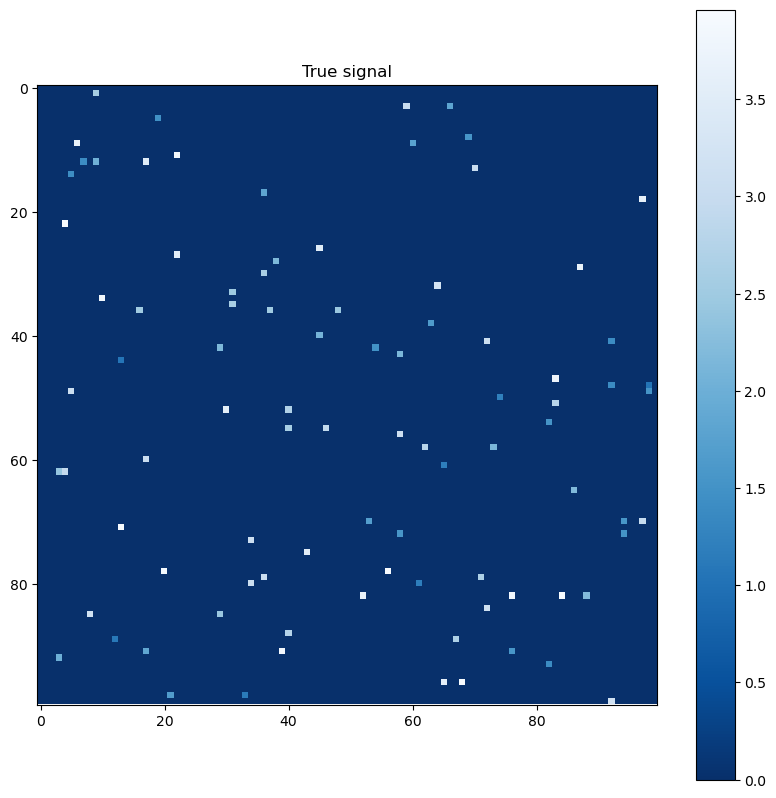

In [3]:

# Set example size
M, N = 100, 100
img_shape = (M,N)

# Draw random image
np.random.seed(1)
p = np.random.binomial(1, 0.01, size=img_shape).astype(np.float64)
q = np.random.uniform(low=1, high=4, size=img_shape).astype(np.float64)
image = p*q

plt.figure(figsize=(10,10))
plt.imshow(image, cmap="Blues_r")
plt.title("True signal")
plt.colorbar()
plt.show()

/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_97136/847896635.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


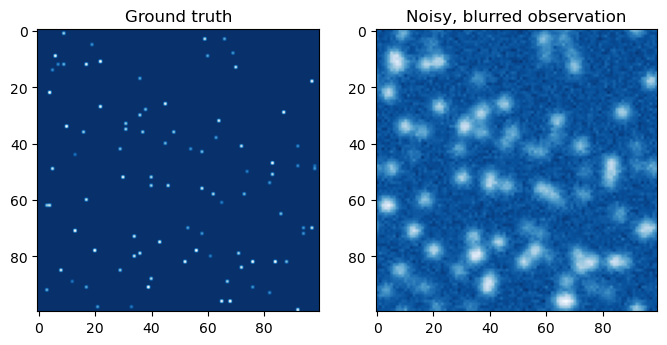

In [4]:

# Make blurring operator
blur_sigma = np.array(2.0).astype(np.float64) # standard deviation of the blur
blur_op = jlinops.Gaussian2DBlurOperator(image.shape, blur_sigma=2)

# Blurred image
blurred_image = blur_op.matvec_shaped(image)

# Add some noise
noise_sigma = 0.01
noise_var = noise_sigma**2
noisy_image = blurred_image + noise_sigma*np.random.normal(size=image.shape)

# Plot
fig, axs = plt.subplots(1, 2, figsize=(8,5))
axs[0].imshow(image, cmap="Blues_r")
axs[0].set_title("Ground truth")
axs[1].imshow(noisy_image, cmap="Blues_r")
axs[1].set_title("Noisy, blurred observation")
fig.show()

In [5]:
#R = jlinops.Neumann2D(image.shape)
R = jlinops.IdentityOperator((M*N, M*N))

In [16]:
rmmgks_solver = RIASGKS(blur_op, R, noisy_image.flatten(), noise_var=noise_var)
#data = rmmgks_solver.solve(n_iter=1000, init_dim=10, kmin=10, kmax=25, hyperpr_r=1.0, hyperpr_beta=1.5 + 1e-3, x_true=image.flatten(), regparam="dp", plotting=True, pdf_name="mgcv_1d_deblurring_mmgks.pdf", gcv_gamma=0.1, helping=True)
data = rmmgks_solver.solve(n_iter=1000, init_dim=10, kmin=5, kmax=25, hyperpr_r=-1.0, hyperpr_beta=1.0, x_true=image.flatten(), regparam="dp", plotting=True, pdf_name="mgcv_1d_deblurring_mmgks.pdf", gcv_gamma=0.1, helping=True)

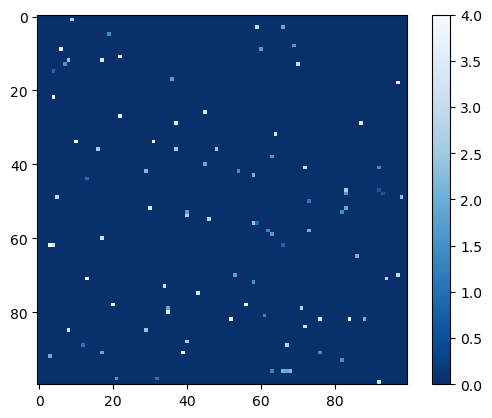

In [20]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r", vmin=0, vmax=4)
plt.colorbar()
plt.show()

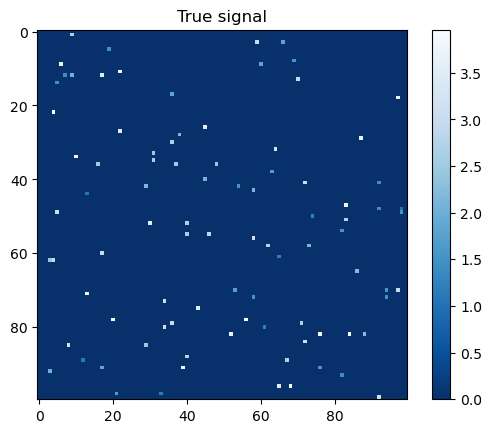

In [18]:

plt.imshow(image, cmap="Blues_r")
plt.title("True signal")
plt.colorbar()
plt.show()

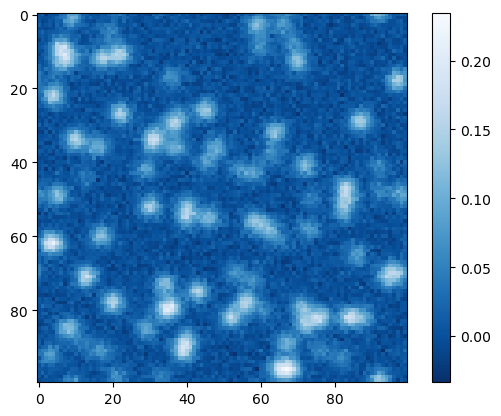

In [19]:
plt.imshow(noisy_image, cmap="Blues_r")
plt.colorbar()
plt.show()

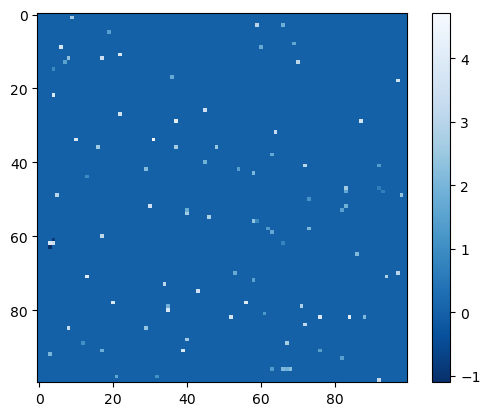

In [23]:
plt.imshow(data["x"].reshape((M,N)), cmap="Blues_r")
plt.colorbar()
plt.show()

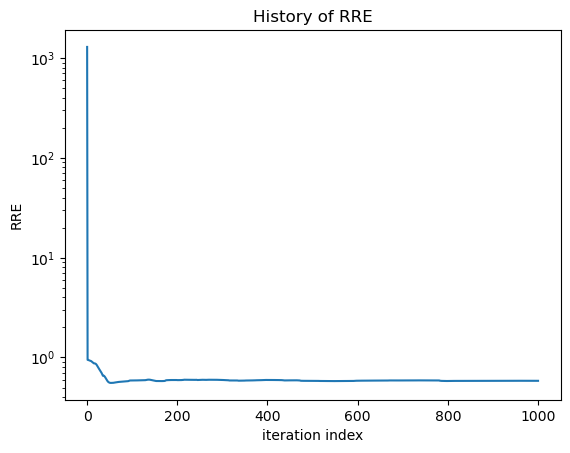

In [24]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

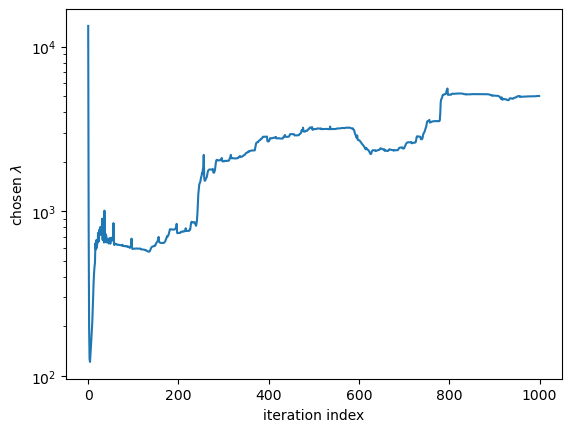

In [25]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

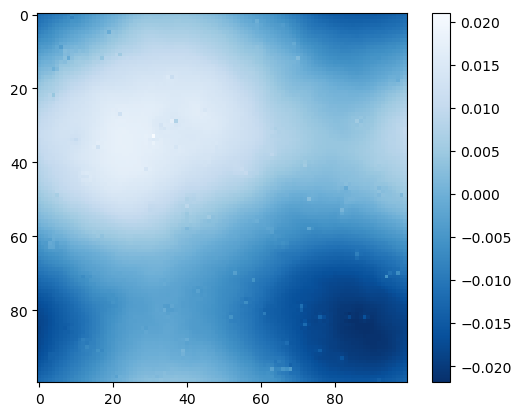

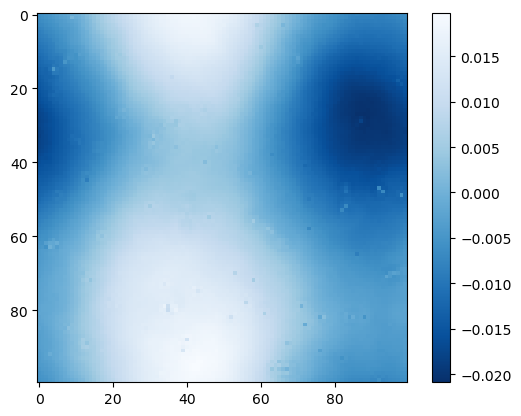

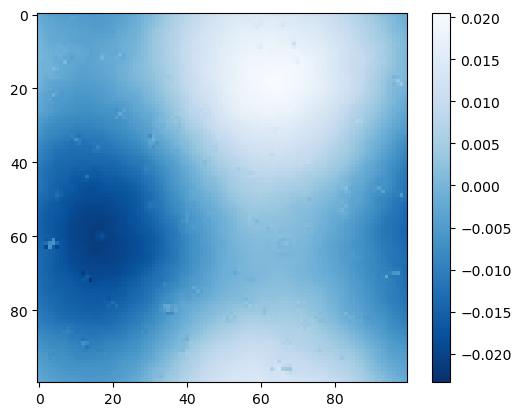

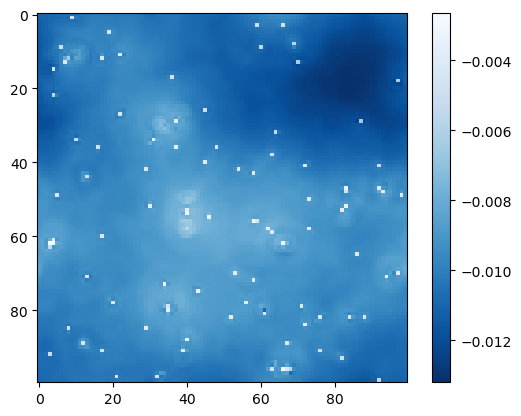

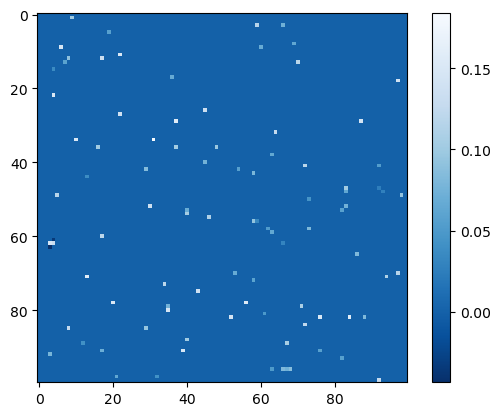

In [28]:
for j in range(5):
    tmp = data["V"][:,j].reshape((M,N))
    plt.figure()
    plt.imshow(tmp, cmap="Blues_r")
    plt.colorbar()

In [ ]:
 bhgyt3,,,,,,e